# STW MCTI: Data Analysis

**Purpose:** Use flow and water-quality (WQ) data to inform the choice and sizing of a nature-based solution (NbS) for storm overflow, i.e. flow above 25 L/s after primary settlement.

**Notebook structure**
1. Setup and configuration
2. Data cleaning and merging
3. Flow and storm characterisation
4. Water quality vs flow
5. Permit compliance and required removal
6. Summary for the team

**Key definitions**
- Storm day: mean daily flow > 25 L/s.
- Excess flow: `max(0, flow - 25)` L/s, the part sent to the NbS.
- Permit limits (mg/l): suspended solids (SS) 65, BOD 100, COD 340, ammoniacal nitrogen (NH3N) 20.

**Limitations**
- Flow data (daily) only covers 1 Jan 2020 to 19 Dec 2023, so WQ samples collected in 2024 cannot be matched to flow.
- WQ samples are taken roughly monthly from 14 Jan 2020 to 3 Dec 2024 (12 per year). However, 5 months have two samples and 5 months have none.
- Flow is a daily mean, so within-day peaks are hidden, whereas WQ values are single grab samples taken at one time of day.
- Only 11 WQ samples fall on storm days (with both flow and WQ data), so storm vs no-storm WQ comparisons carry wide uncertainty.
- All WQ samples are crude sewage (pre-primary settlement), whereas the NbS receives flow after primary settlement.

## 1. Setup and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

#Paths
DATA_DIR = Path(".") #Current path
FLOW_FILE = DATA_DIR / "mean_daily_flow_20_23.csv"
WQ_FILE = DATA_DIR / "wq_data_20_24.csv"

OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True) #Create path, if doesn't already exist

#Project constants (from the brief)
STORM_THRESHOLD = 25.0          
PERMIT = {"SS": 65, "BOD": 100, "COD": 340, "NH3N": 20} # mg/l
PARAMETERS = list(PERMIT)
LABELS = {"SS": "Suspended solids", "BOD": "BOD", "COD": "COD", "NH3N": "Ammoniacal nitrogen"}
L_S_TO_M3_DAY = 86.4 # 1 L/s sustained for a day = 86.4 m3

def save_fig(name):
    """Save the current figure to outputs/figures."""
    plt.tight_layout() #Automatically adjust spacing to avoid overlap
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 2. Data cleaning and merging

In this section, we will prepare the two datasets for analysis. We will clean and check each file separately (2.1 and 2.2), then merge them on date so that WQ samples can be classed as storm or no storm (2.3).

### 2.1 Flow data
The flow file has two columns: "Date" and "Mean". To make the data ready for analysis, we will:
- Convert the values in the "Date" column from strings to datetime objects, so that dates can be sorted, grouped by year and month and matched to the WQ samples.
- Rename the "Mean" column to something more descriptive to make clear what it measures and its units.
- Check that:
    - No dates are missing or duplicated.
    - No mean flow values are missing or negative.
- Add the following columns:
    - "storm": True if the day is a storm day (mean flow > 25 L/s), otherwise False.
    - "excess_ls": The excess flow above the 25 L/s threshold, in L/s (0 on no-storm days).
    - "excess_m3": The volume of excess flow over the day, in m³ (0 on no-storm days).
    - "year" and "month": The year and month from the "date" column.

In [2]:
flow = pd.read_csv(FLOW_FILE)

#Convert "Date" values to datetime objects
flow["date"] = pd.to_datetime(flow["Date"], format="%d-%b-%y")
flow = flow.sort_values("date").reset_index(drop=True)
flow.drop("Date", axis=1, inplace=True)

#Rename "Mean" column
flow.rename(columns={"Mean": "mean_flow_ls"}, inplace=True)   

#Quality checks
full_range = pd.date_range(flow["date"].min(), flow["date"].max(), freq="D") #Expected dates
missing_dates = full_range.difference(flow["date"]) #Check for missing dates
flow_checks = {
    "rows": len(flow),
    "first date": flow["date"].min().date(),
    "last date": flow["date"].max().date(),
    "missing dates": len(missing_dates),
    "duplicate dates": int(flow["date"].duplicated().sum()),
    "missing flow values": int(flow["mean_flow_ls"].isna().sum()),
    "negative flow values": int((flow["mean_flow_ls"] < 0).sum()),
}
pd.Series(flow_checks, name="Flow data checks").to_frame()

,Flow data checks
rows,1449
first date,2020-01-01
last date,2023-12-19
missing dates,0
duplicate dates,0
missing flow values,0
negative flow values,0


In [3]:
#Add columns
flow["storm"] = flow["mean_flow_ls"] > STORM_THRESHOLD
flow["excess_ls"] = (flow["mean_flow_ls"] - STORM_THRESHOLD).clip(lower=0)
flow["excess_m3"] = flow["excess_ls"] * L_S_TO_M3_DAY
flow["year"] = flow["date"].dt.year
flow["month"] = flow["date"].dt.month

### 2.2 Water-quality data

The water-quality file has seven columns: "Sample Date", "Sample Time", "Sample Type", "Determinand Name", "<>", "Result" and "Units". To make the data ready for analysis, we will:
- Convert the strings in the "Sample Date" and "Sample Time" columns to datetime objects, so that samples can be sorted, grouped by month and year and matched to the flow data.
- Check whether any months have no sample or more than one sample (the samples are expected to be roughly monthly), since gaps or extra samples affect how representative the samples are.
- Check that:
    - All sample types are "Crude Sewage" and none are missing.
    - All determinand names are one of "SS", "BOD (2MG/L ATU) 5 DAY SUPPRESSED", "AMMONIACAL NITROGEN AS N" or "COD TOTAL" and none are missing, so that every result can be assigned to one of the four parameters.
    - All values in "<>" are either missing, "<" (the true result is below the value in the "Result" column, which is the lowest value that can be measured reliably) or ">" (the true result is above the value in the "Result" column), so that we know whether any results need special treatment as censored values.
    - All results are non-negative numbers and none are missing.
    - All units are "mg/l" and none are missing, so that results can be compared directly with each other and with the permit limits.
- Replace the long determinand names with short labels (SS, BOD, NH3N, COD), to make the tables and plots easier to read.
- Pivot the table so that each sampling date is a row and each parameter is a column (the file currently has one row per parameter per sample).
- Add the sample year and month as separate columns, so that samples can be grouped or checked by these values later.

In [4]:
wq_raw = pd.read_csv(WQ_FILE)

#Convert relevant values to datetime objects
wq_raw["date"] = pd.to_datetime(wq_raw["Sample Date"], format="%d/%m/%Y") #Convert strings to datetime objects
wq_raw["time"] = pd.to_datetime(wq_raw["Sample Time"], format="%H:%M:%S") #Convert strings to datetime objects

#Convert values in the "Result" column to numeric values
wq_raw["result"] = pd.to_numeric(wq_raw["Result"], errors="coerce")

#Quality checks
sample_dates = wq_raw["date"].drop_duplicates()
samples_per_month = sample_dates.dt.to_period("M").value_counts().sort_index()
full_months = pd.period_range(sample_dates.min(), sample_dates.max(), freq="M")
missing_months = full_months.difference(pd.PeriodIndex(samples_per_month.index))
multi_sample_months = samples_per_month[samples_per_month > 1]

n_censored = wq_raw["<>"].notna().sum()
dupes = wq_raw.duplicated(["date", "Determinand Name"]).sum()

wq_checks = {
    "rows (long format)": len(wq_raw),
    "sampling dates": wq_raw["date"].nunique(),
    "first sample date": wq_raw["date"].min().date(),
    "last sample dates": wq_raw["date"].max().date(),
    "months with no sample": len(missing_months),
    "months with no sample (list)": ", ".join(missing_months.astype(str)),
    "months with more than one sample": len(multi_sample_months),
    "months with more than one sample (list)": ", ".join(multi_sample_months.index.astype(str)),
    "duplicate date+parameter": int(dupes),
    "sample types": ", ".join(wq_raw["Sample Type"].unique()),
    "missing sample types": int(wq_raw["Sample Type"].isna().sum()),
    "determinand names": ", ".join(wq_raw["Determinand Name"].unique()),
    "missing determinand names": int(wq_raw["Determinand Name"].isna().sum()),
    "censored results (<>)": int(n_censored),
    "negative result values": int((wq_raw["result"] < 0).sum()),
    "missing results": int(wq_raw["result"].isna().sum()),
    "units": ", ".join(wq_raw["Units"].unique()),
    "missing units": int(wq_raw["Units"].isna().sum()),
}

pd.Series(wq_checks, name="Water-quality checks").to_frame()

,Water-quality checks
rows (long format),240
sampling dates,60
first sample date,2020-01-14
last sample dates,2024-12-03
months with no sample,5
months with no sample (list),"2020-08, 2020-12, 2021-12, 2022-12, 2024-06"
months with more than one sample,5
months with more than one sample (list),"2020-07, 2020-09, 2021-03, 2022-11, 2024-07"
duplicate date+parameter,0
sample types,Crude Sewage


In [5]:
#Replace long determinand names with short labels
wq_raw["parameter"] = wq_raw["Determinand Name"].map({
    "SS": "SS",
    "BOD (2MG/L ATU) 5 DAY SUPPRESSED": "BOD",
    "AMMONIACAL NITROGEN AS N": "NH3N",
    "COD TOTAL": "COD",
})

#Pivot to one row per sampling date
wq = (wq_raw.pivot_table(index="date", columns="parameter", values="result")[PARAMETERS])                     

#Add sample year and month as separate column 
wq["year"] = wq.index.year
wq["month"] = wq.index.month

### 2.3 Merge and storm flag

To link the flow and water-quality data, we will:
- Left-join the flow data onto the water-quality dates (keeping every water-quality date), so that each sample has the mean flow recorded on the day it was taken.
- Use this flow to classify each sample as **storm** (flow > 25 L/s) or **no storm** (flow <= 25 L/s). Samples taken after the last flow record cannot be classified, so we will label them **no flow data**.
- Create two DataFrames: `df`, which contains all sample dates, and `dfm`, which contains only the dates with both flow and water-quality data. We will use `dfm` for the analysis that compares water quality with flow.

In [6]:
df = wq.join(flow.set_index("date")[["mean_flow_ls", "storm", "excess_ls"]], how="left")
df["regime"] = np.select(
    [df["mean_flow_ls"].isna(), df["storm"] == True],
    ["No flow data", "Storm"],
    default="No storm",
)
df = df.drop(columns="storm")

# Matched dataset: only samples with a flow value (used for all flow-vs-quality analysis)
dfm = df[df["mean_flow_ls"].notna()].copy()
dfm["regime"] = pd.Categorical(dfm["regime"], categories=["No storm", "Storm"], ordered=True)

summary = pd.DataFrame({
    "Samples": df["regime"].value_counts(),
}).reindex(["No storm", "Storm", "No flow data"]).fillna(0).astype(int)
summary.loc["Total"] = summary.sum()
summary

,Samples
regime,
No storm,37
Storm,11
No flow data,12
Total,60


In [7]:
# Save cleaned datasets
flow.to_csv(OUT_DIR / "flow_clean.csv", index=False)
wq.to_csv(OUT_DIR / "wq_clean.csv")
df.to_csv(OUT_DIR / "wq_flow_merged.csv")
dfm.to_csv(OUT_DIR / "wq_flow_merged_matched.csv")
print("Saved: flow_clean.csv, wq_clean.csv, wq_flow_merged.csv, wq_flow_merged_matched.csv ->", OUT_DIR.resolve())

Saved: flow_clean.csv, wq_clean.csv, wq_flow_merged.csv, wq_flow_merged_matched.csv -> C:\Users\emily\Documents\Careers\MCTI\outputs


## 3. Flow and storm characterisation

In this section we will use the flow record alone (2020 to 2023) to analyse the storm flows that the NbS would receive.

**Questions:**
- How often does the storm overflow operate?
- How big are the flows?
- What design flow (maximum flow rate the NbS is designed to treat) gives a sensible trade-off between size and volume treated?

### 3.1 Storm frequency

In this subsection, we will:
- Calculate the number and percentage of storm days in each year, to see whether storm frequency is consistent from year to year or varies. 
- Group all four years by calendar month and calculate the percentage of days in each month that are storm days, to reveal any seasonal pattern. 

Together, these results will show how regularly the NbS would be needed and in which months it would be under most pressure. This matters for design because a system that must operate frequently, or mainly in particular seasons, has different requirements from one that is only needed occasionally.

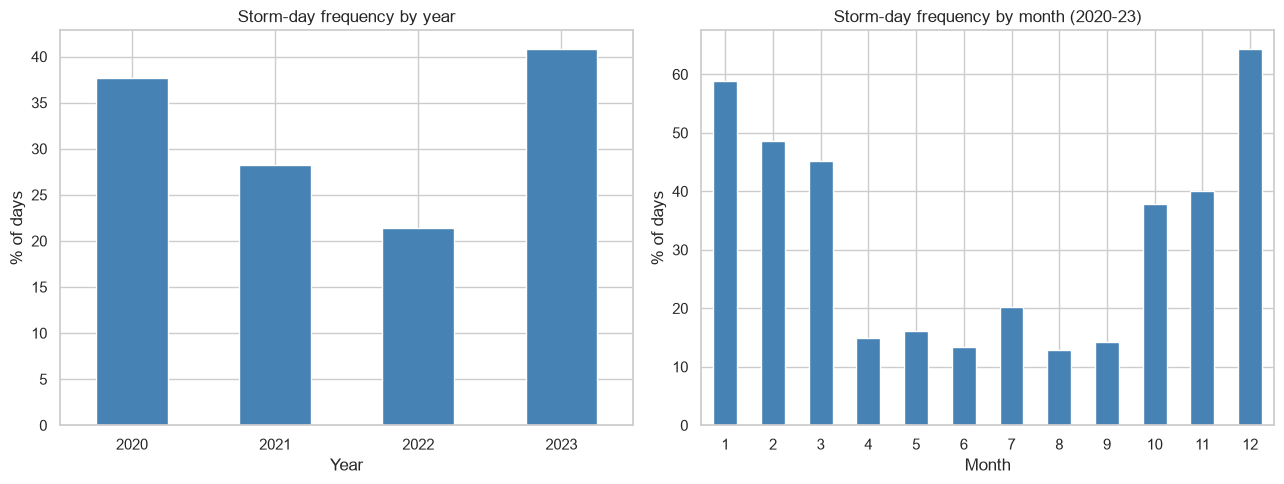

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, period, title in zip(axes, ["year", "month"], ["Storm-day frequency by year", "Storm-day frequency by month (2020-23)"]):
    (flow.groupby(period)["storm"].mean() * 100).plot.bar(ax=ax, color="steelblue", rot=0)
    ax.set(title=title, xlabel=period.capitalize(), ylabel="% of days")
save_fig("flow_storm_frequency")

**Analysis of storm frequency by year and month**

- **By year:** The percentage of storm days ranges from about 21% in 2022 to about 41% in 2023, with 2020 at about 38% and 2021 at about 28%. There is no clear trend, as the frequency fell from 2020 to 2022 and then rose sharply in 2023. With only four years, this is best treated as natural year-to-year variability.
- **By month:** Storms show a strong seasonal pattern. From October to March, about 38 to 64% of days are storm days, peaking in December (about 64%) and January (about 59%). From April to September, only about 13 to 20% of days are storm days. Overall, about 49% of days are storm days in October to March, compared with about 15% in April to September.

**Implication for the NbS:** Storm flow is concentrated in the colder, wetter months, so the NbS will be under the most pressure in winter, when about half of all days involve storm flow and recovery time between events is shortest. The design should be assessed against winter conditions and the NbS must keep its performance in cold weather, since biological treatment processes such as ammonia removal are generally slower at lower temperatures. Conversely, the system is needed much less in summer, when storm days make up only about one day in seven, so it must also remain healthy during long periods with little or no storm flow, for example by keeping vegetation alive. The large differences between years (21% to 41% of days) also mean the system should be assessed against the wetter years, not the average year.

### 3.2 Flow frequency curve

In this subsection, we will plot a flow frequency curve (also called a flow duration curve) to show how often different flow levels occur at the site over 2020 to 2023. Each point on the curve will give the percentage of days on which the mean daily flow was equal to or greater than the flow on the x-axis. We will mark the 25 L/s storm threshold with a red vertical line: following it up to the curve and across to the y-axis will give the share of days classed as storm days. The part of the curve to the right of the line will represent the excess flow that the NbS would need to treat.

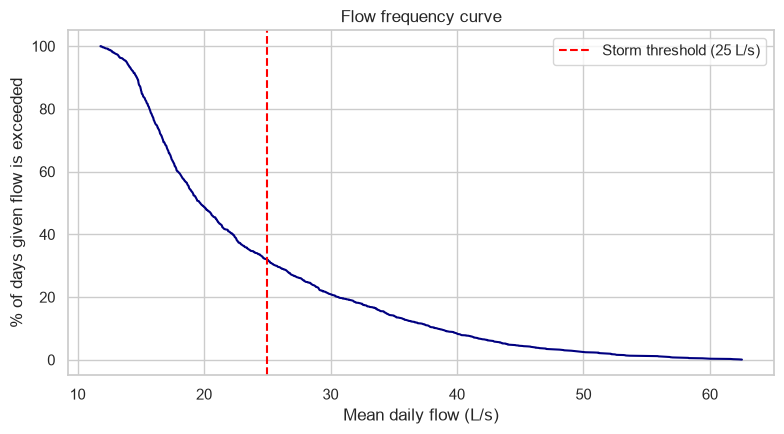

In [9]:
sorted_flow = np.sort(flow["mean_flow_ls"].values)[::-1] #Decreasing order
exceedance = 100 * np.arange(1, len(sorted_flow) + 1) / len(sorted_flow) #exceedance[i] = the percentage of days that have a flow of at least sorted_flow[i]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sorted_flow, exceedance, color="navy")
ax.axvline(STORM_THRESHOLD, color="red", ls="--", label=f"Storm threshold ({STORM_THRESHOLD:.0f} L/s)")
ax.set(xlabel="Mean daily flow (L/s)", ylabel="% of days given flow is exceeded", title="Flow frequency curve")
ax.legend()
save_fig("flow_frequency_curve")

**Analysis of the flow frequency curve**

Flow is never below about 12 L/s and the median flow is about 20 L/s, already close to the 25 L/s threshold. Flows exceed 25 L/s on about 32% of days.

The curve is steep up to the threshold, so most flows lie between about 12 and 25 L/s, and then flattens into a long tail of rare high flows: about 21% of days exceed 30 L/s, about 8% exceed 40 L/s and only about 2% exceed 50 L/s. The highest recorded flow is about 62.5 L/s.

**Implication for the NbS:** Most storm days involve only a modest excess over 25 L/s, so a system sized for the maximum flow would be largely unused. The design flow can therefore be set below the peak while still treating most of the storm volume (see section 3.4).

### 3.3 Storm events

In this subsection, we will analyse storm events (runs of consecutive storm days), since the NbS must handle consecutive storm days, not just isolated ones. We will:
- Group consecutive storm days into events and summarise the duration, peak mean flow and excess volume of each event, since these determine how much water the system must hold and treat.
- Plot the distributions of event duration and excess volume, to show how typical events compare with the largest ones.
- Group the non-storm days between events into dry gaps and summarise their duration and mean flow, since these determine how long the system has to drain and recover.

**Limitations:**
- Events are identified from daily mean flows, so storms shorter than a day cannot be distinguished.
- The record begins and ends on a storm day, so the first and last events may be truncated.

In [10]:
# Assigns a new event ID whenever the storm status changes, grouping consecutive storm or non-storm days
flow["event_id"] = (flow["storm"] != flow["storm"].shift()).cumsum() 

events = (flow[flow["storm"]].groupby("event_id")
          .agg(start=("date", "min"), end=("date", "max"),
               duration_days=("date", "size"),
               peak_mean_flow_ls=("mean_flow_ls", "max"),
               excess_volume_m3=("excess_m3", "sum"))
          .reset_index(drop=True))

print(f"Number of storm events: {len(events)}")
events[["duration_days", "peak_mean_flow_ls", "excess_volume_m3"]].describe().T

Number of storm events: 106


,count,mean,std,min,25%,50%,75%,max
duration_days,106.00,4.37,7.08,1.00,1.00,2.00,4.00,41.00
peak_mean_flow_ls,106.00,36.37,9.88,25.08,28.53,33.64,41.60,62.53
excess_volume_m3,106.00,"3,952.98","8,786.96",7.11,322.22,888.97,"3,069.45","53,742.98"


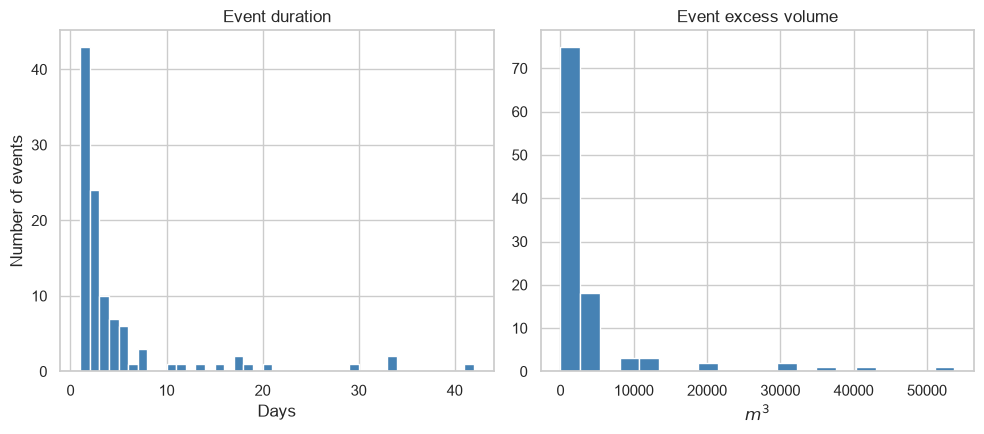

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].hist(events["duration_days"], bins=range(1, int(events["duration_days"].max()) + 2), color="steelblue", edgecolor="white")
axes[0].set(title="Event duration", xlabel="Days", ylabel="Number of events")
axes[1].hist(events["excess_volume_m3"], bins=20, color="steelblue", edgecolor="white")
axes[1].set(title="Event excess volume", xlabel="$m^3$")
save_fig("flow_event_distributions")

In [12]:
# Dry gaps: runs of consecutive non-storm days between storm events
dry_gaps = (flow[~flow["storm"]].groupby("event_id")
            .agg(start=("date", "min"), end=("date", "max"),
                 duration_days=("date", "size"),
                 mean_flow_ls=("mean_flow_ls", "mean"))
            .reset_index())

print(f"Number of dry gaps between storm events: {len(dry_gaps)}")
dry_gaps[["duration_days", "mean_flow_ls"]].describe().T

Number of dry gaps between storm events: 105


,count,mean,std,min,25%,50%,75%,max
duration_days,105.00,9.39,12.26,1.00,1.00,5.00,13.00,71.00
mean_flow_ls,105.00,20.00,2.91,14.09,17.69,20.42,22.57,24.96


**Analysis of storm events and dry gaps**

**Storm events**

The 463 storm days group into 106 events, which are mostly short and small but include a few very large ones. The histograms show the same pattern: most events last a few days and have modest volumes, with a long tail of rarer, larger events.

- **Duration:** The median event lasts 2 days, a quarter last a single day and 75% last 4 days or fewer. The mean (4.4 days) is well above the median and the longest event lasts 41 days, so a few prolonged events pull the average up.
- **Peak flow:** The median event peaks at about 34 L/s (mean about 36 L/s) and three quarters of events peak below about 42 L/s, so typical events exceed the 25 L/s threshold only moderately. Only a few events approach the maximum of 62.5 L/s.
- **Excess volume:** Volumes are strongly right-skewed. The median event produces about 890 m³ of excess flow, but the mean is about 3,950 m³ and the largest event reaches about 53,700 m³, roughly 60 times the median and about 13% of the total excess volume over the four years (about 419,000 m³).

**Dry gaps between events**

Between the 106 events there are 105 dry gaps (runs of consecutive non-storm days), which vary widely in length but are often short.

- **Duration:** The median gap is 5 days and the mean (9.4 days) is higher because of a few long dry spells, the longest being 71 days. A quarter of gaps last only 1 day and 75% last 13 days or fewer. Gaps are typically longer than events (median 5 vs 2 days), consistent with storm days making up about a third of all days.
- **Flow during gaps:** The mean flow during a gap is about 20 L/s (range 14 to 25 L/s), so flows between events stay fairly close to the 25 L/s threshold. During these gaps the NbS receives no excess flow and can drain and recover.

**Implication for the NbS:** A typical event is brief and involves a modest volume, so a system sized for the typical case would handle most events. However, the rare long, high-volume events contribute a disproportionate share of the total volume and would test the system's capacity, for example through saturation. The recovery window is also short: half of the gaps last 5 days or less and a quarter last a single day, so the system may have to treat the next event before it has fully recovered from the last. The design should therefore be checked against the larger events and against the 1 to 5 day gaps (not the longer dry spells), and we must decide what level of bypass during extreme events is acceptable.

### 3.4 Design-flow trade-off

The **design flow** is the maximum excess flow (above 25 L/s) that the NbS is built to treat; any excess above it bypasses the system. A larger design flow treats more of the storm volume but needs a larger, more costly system. We will therefore calculate the share of the total storm volume treated at each design flow and plot it as a curve, to find a sensible balance between the size of the system and the volume it treats.

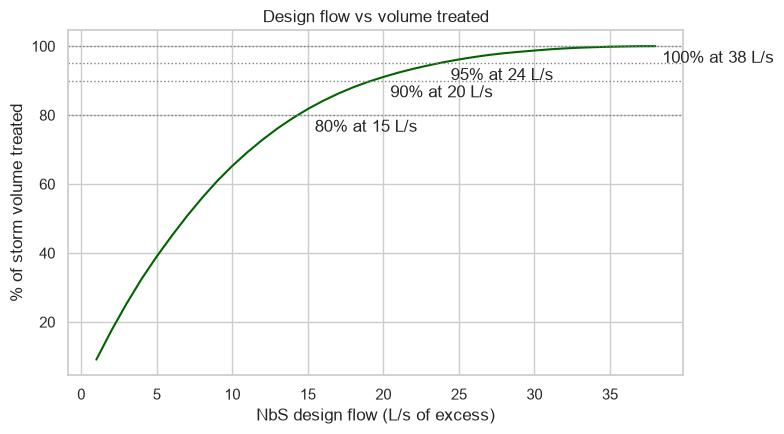

,pct_volume_treated
5.00,39.01
10.00,65.27
15.00,81.77
20.00,91.06
25.00,96.14
30.00,98.72


In [13]:
q_values = np.arange(1, np.ceil(flow["excess_ls"].max()) + 1)
coverage = [flow["excess_ls"].clip(upper=q).sum() / flow["excess_ls"].sum() * 100 for q in q_values]
coverage = pd.Series(coverage, index=q_values, name="pct_volume_treated")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(coverage.index, coverage.values, color="darkgreen")
for target in (80, 90, 95, 100):
    q_t = coverage[coverage >= target].index[0]
    ax.axhline(target, color="grey", ls=":", lw=1)
    ax.annotate(f"{target}% at {q_t:.0f} L/s", (q_t, target), textcoords="offset points", xytext=(5, -12))
ax.set(xlabel="NbS design flow (L/s of excess)", ylabel="% of storm volume treated",
       title="Design flow vs volume treated")
save_fig("design_flow_coverage")

pd.DataFrame({"pct_volume_treated": coverage.loc[[5, 10, 15, 20, 25, 30]]})

**Analysis of the design-flow trade-off**

The curve shows diminishing returns: each extra litre per second of design flow treats less additional storm volume than the one before. A design flow of 10 L/s treats about 65% of storm volume, 20 L/s about 91% and 30 L/s about 99%, whereas treating 100% requires about 38 L/s. The last few percent are expensive because the highest flows are rare.

**Implication for the NbS:** The curve starts to level off at about 15 to 20 L/s, which treats roughly 80 to 90% of storm volume. Sizing well beyond this would require a much larger system for a small gain, while sizing well below it would leave a large share of storm volume untreated. A design flow of about 20 L/s (a total site flow of about 45 L/s) is therefore a sensible starting point for discussion. The final choice depends on factors outside this dataset, such as available land, cost and the level of bypass allowed.

## 4. Water quality vs flow

Section 3 described the storm flows the NbS would receive. This section will examine the quality of that water. Since the NbS only has to treat storm flow, we will first compare pollutant concentrations on storm and no-storm days (4.1) and then examine how concentrations change continuously with flow (4.2).

**Limitation:** Only 11 of the 48 samples with flow data fall on storm days, and their flows only reach about 47 L/s, compared with a maximum of about 62.5 L/s in the flow record. All conclusions in this section should therefore be treated as indicative rather than conclusive.

### 4.1 No storm vs storm concentrations

In this subsection, we will compare the concentration of each parameter on no-storm and storm days, to see whether storm flow dilutes the sewage. We will first compare the two groups visually using box plots (4.1.1) and then test statistically whether the differences are larger than chance variation (4.1.2).

#### 4.1.1 Box plots

We will plot one box plot per parameter, comparing no-storm and storm days. Each sample will be shown as a black point and the permit limit as a red dashed line, so that we can see both the spread of the data and how far the concentrations are above the permit. The box shows the middle 50% of the samples and the whiskers extend to 1.5 × the interquartile range. Points beyond the whiskers are outliers, which are retained in the analysis.

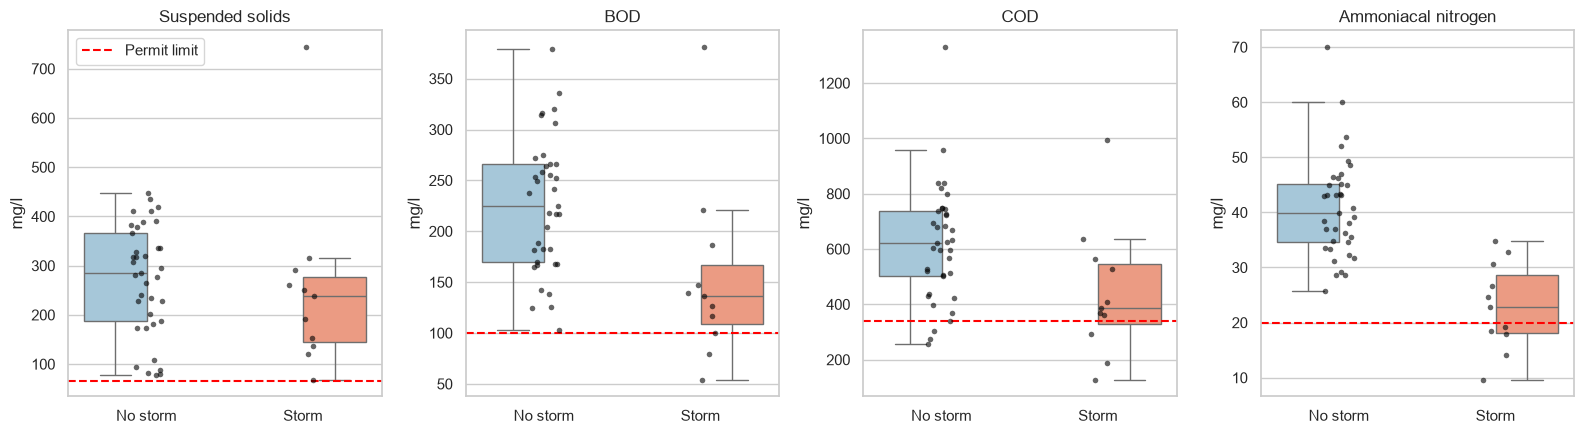

In [14]:
long = dfm.melt(id_vars=["mean_flow_ls", "regime"], value_vars=PARAMETERS,
                var_name="parameter", value_name="mg_l")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, par in zip(axes, PARAMETERS): #zip(axes, PARAMETERS) pairs each subplot with one parameter
    d = long[long["parameter"] == par]
    sns.boxplot(data=d, x="regime", y="mg_l", order=["No storm", "Storm"], showfliers=False,
                palette=["#9ecae1", "#fc9272"], hue="regime", legend=False, ax=ax)
    sns.stripplot(data=d, x="regime", y="mg_l", order=["No storm", "Storm"], color="black", size=4, alpha=0.6, ax=ax)
    ax.axhline(PERMIT[par], color="red", ls="--", label="Permit limit")
    ax.set(title=LABELS[par], xlabel="", ylabel="mg/l")
axes[0].legend()
save_fig("wq_dry_vs_storm")

**Analysis of the box plots**

- **Dilution:** Storm-day concentrations are generally lower than on no-storm days, which is likely due to rainwater diluting the sewage.
- **Permit limits:** The median storm-day concentration of every parameter is still above its permit limit. Every matched suspended solids sample exceeds its limit. Therefore, the overflow still needs treatment.
- **Spread:** Storm samples are widely spread, with a few extreme values (for example a suspended solids sample of about 745 mg/l). These are real measurements and are retained.

The next subsection tests whether the differences between storm and no-storm samples are larger than chance variation.

#### 4.1.2 Statistical comparison

The box plots suggest that storm-day concentrations are lower. However, with so few storm samples we need to check whether the differences are larger than chance variation. For each parameter, we will calculate:

- **Difference of medians (storm minus no storm):** The median concentration on storm days minus the median concentration on no-storm days, which gives the size and direction of the difference. We use medians because they are less affected by outliers than means.
- **95% bootstrap confidence interval:** A plausible range for the true difference of medians. We will resample the storm and no-storm samples with replacement 10,000 times, calculate the difference between the two resampled medians each time and take the middle 95% of these differences. If the interval excludes zero, the difference is unlikely to be due to chance alone. If it includes zero, the data are consistent with no real difference, so we cannot conclude that storm and no-storm concentrations differ.
- **Mann-Whitney U test p-value:** A non-parametric test of whether values in one group tend to be larger than in the other (the null hypothesis is that both groups come from the same distribution). A small p-value (for example below 0.05) indicates a difference, but with so few storm samples it should be read alongside the confidence interval, not on its own.
- **P(storm > no storm):** The probability that a randomly chosen storm sample has a higher concentration than a randomly chosen no-storm sample. It is calculated as the Mann-Whitney U statistic divided by the number of storm/no-storm pairs (ties count as half). A value of 0.5 means no difference, values below 0.5 mean storm samples tend to be lower and values above 0.5 mean they tend to be higher.

In [15]:
def bootstrap_median_diff(storm, no_storm, n_boot=10000, seed=42):
    """95% bootstrap CI for (median storm - median no storm)."""
    rng = np.random.default_rng(seed)
    diffs = [np.median(rng.choice(storm, len(storm))) - np.median(rng.choice(no_storm, len(no_storm)))
             for _ in range(n_boot)] #Sampling is with replacement, therefore, original values may appear multiple times, while others may not appear
    return np.percentile(diffs, [2.5, 97.5])

rows = []
for par in PARAMETERS:
    no_storm = dfm.loc[dfm["regime"] == "No storm", par].values
    storm = dfm.loc[dfm["regime"] == "Storm", par].values
    u, p = stats.mannwhitneyu(storm, no_storm, alternative="two-sided")
    lo, hi = bootstrap_median_diff(storm, no_storm)
    rows.append({
        "parameter": par,
        "n no storm": len(no_storm), "n storm": len(storm),
        "Median no storm": np.median(no_storm), "Median storm": np.median(storm),
        "Diff (storm-no-storm)": np.median(storm) - np.median(no_storm),
        "95% CI low": lo, "95% CI high": hi,
        "P(storm > no storm)": u / (len(storm) * len(no_storm)),   # common-language effect size
        "Mann-Whitney p": p,
    })
dry_vs_storm = pd.DataFrame(rows).set_index("parameter")
dry_vs_storm

,n no storm,n storm,Median no storm,Median storm,Diff (storm-no-storm),95% CI low,95% CI high,P(storm > no storm),Mann-Whitney p
parameter,,,,,,,,,
SS,37,11,286.00,238.00,-48.00,-167.00,22.00,0.37,0.19
BOD,37,11,225.00,136.00,-89.00,-138.00,-31.00,0.21,0.00
COD,37,11,623.00,388.00,-235.00,-339.00,-33.00,0.26,0.02
NH3N,37,11,39.90,22.90,-17.00,-24.80,-8.40,0.06,0.00


**Analysis of the statistical comparison**

BOD, COD and ammoniacal nitrogen are clearly lower on storm days, which is consistent with dilution, whereas suspended solids shows no clear difference.

- **Ammoniacal nitrogen, BOD and COD (clear dilution):** All the measures agree.
    - The median concentration is 38 to 43% lower on storm days (ammoniacal nitrogen -17 mg/l, BOD -89 mg/l, COD -235 mg/l).
    - The 95% confidence intervals lie entirely below zero.
    - The Mann-Whitney p-values are below 0.05 (0.02 for COD and below 0.01 for the others).
    - A storm sample is higher than a no-storm sample in only 6% (ammoniacal nitrogen), 21% (BOD) and 26% (COD) of pairs, so storm samples are usually lower.
- **Suspended solids (no clear dilution):** The measures do not support a real difference.
    - The median is about 17% lower on storm days (-48 mg/l), but the 95% confidence interval includes zero (-167 to +22 mg/l).
    - The p-value (0.19) is well above 0.05.
    - A storm sample is higher than a no-storm sample in 37% of pairs, not far from the 50% expected if there were no difference.

**Implication for the NbS:** Dilution lowers the required removal for ammoniacal nitrogen, BOD and COD, but not for suspended solids. The confidence intervals are wide because there are only 11 storm samples (for example, the COD difference of medians could plausibly be anywhere between about -339 and -33 mg/l).

### 4.2 Concentration vs flow

The comparison above splits the data at the 25 L/s threshold. In this subsection, we will instead use all 48 matched samples and treat flow as a continuous variable, to show how concentration changes as flow increases and whether dilution is gradual.

We will plot one scatter plot per parameter, with mean daily flow on the x-axis and concentration on the y-axis. Each point will be one sample, coloured orange if the flow was above the 25 L/s storm threshold and blue otherwise. Each plot will also include:

- **LOWESS trend line (navy):** A smooth, locally weighted curve that follows the general pattern in the data without assuming a straight line.
- **Storm threshold (grey dotted vertical line):** Marks 25 L/s.
- **Permit limit (red dashed horizontal line):** Points above this line exceed the permit.
- **Spearman correlation (rho):** Shown in each title. It measures how consistently concentration rises or falls with flow, from -1 (always falls as flow rises) to +1 (always rises), with 0 meaning no relationship. It is based on ranks, so it does not assume a straight-line relationship and is less affected by outliers. The p-value indicates whether the relationship is likely to be real or due to chance.

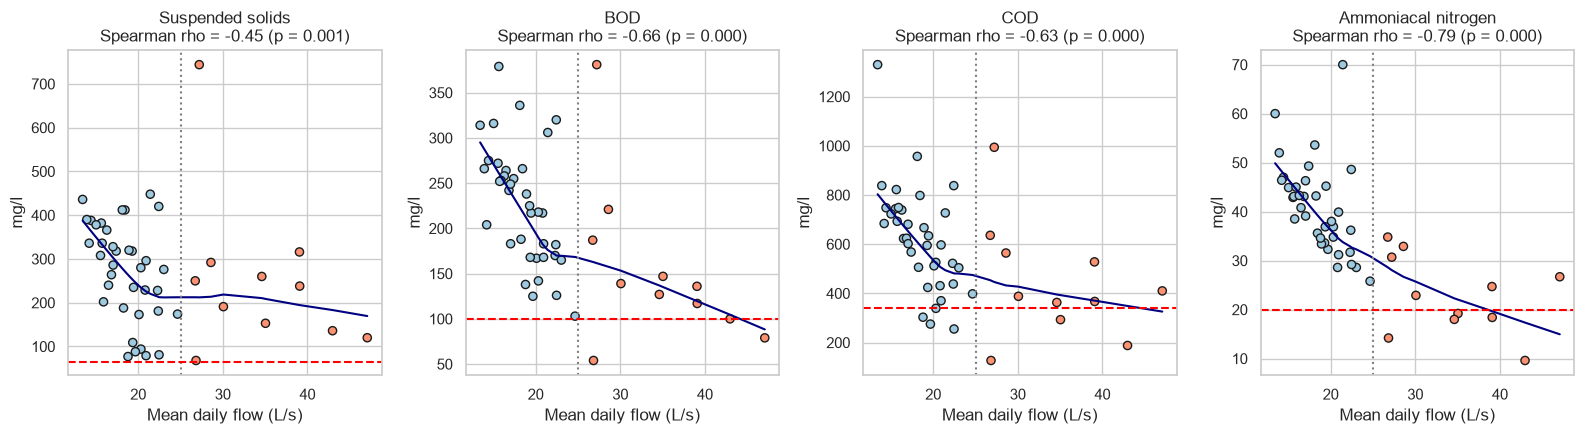

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, par in zip(axes, PARAMETERS):
    x, y = dfm["mean_flow_ls"], dfm[par]
    ax.scatter(x, y, c=np.where(x > STORM_THRESHOLD, "#fc9272", "#9ecae1"), edgecolor="k", s=35)
    smooth = sm.nonparametric.lowess(y, x, frac=0.8)
    ax.plot(smooth[:, 0], smooth[:, 1], color="navy", lw=1.5)
    ax.axvline(STORM_THRESHOLD, color="grey", ls=":")
    ax.axhline(PERMIT[par], color="red", ls="--")
    rho, p = stats.spearmanr(x, y)
    ax.set(title=f"{LABELS[par]}\nSpearman rho = {rho:.2f} (p = {p:.3f})", xlabel="Mean daily flow (L/s)", ylabel="mg/l")
save_fig("wq_vs_flow_scatter")

**Analysis of concentration vs flow**

All four parameters fall as flow rises (negative Spearman correlations), which is consistent with dilution by stormwater. The correlations are moderate to strong and the p-values are at or below 0.001, so the trends are unlikely to be due to chance.

- **Suspended solids (rho = -0.45):** The weakest relationship. Concentrations fall as flow increases up to about 22 L/s, but above that the trend levels off at about 210 mg/l, so further increases in flow bring little additional dilution. The trend stays well above the 65 mg/l limit at all flows, which agrees with the box plot comparison.
- **BOD (rho = -0.66) and COD (rho = -0.63):** Both decline moderately with flow. BOD falls from about 295 mg/l to about 170 mg/l at the 25 L/s threshold, but only reaches the 100 mg/l limit at about 43 to 47 L/s. COD falls from about 800 mg/l to about 470 mg/l at the threshold, but only approaches the 340 mg/l limit at the highest flows.
- **Ammoniacal nitrogen (rho = -0.79):** The strongest relationship. Concentration falls steadily from about 50 mg/l at 13 L/s to about 31 mg/l at the 25 L/s threshold and about 15 mg/l at the highest flows, crossing the 20 mg/l permit limit at about 40 L/s.

**Implication for the NbS:** Dilution lowers the treatment needed for ammoniacal nitrogen, BOD and COD as flow increases, but for most storm flows these concentrations remain above the permit limits, so treatment is still required. Suspended solids benefit least from dilution and are likely to drive the required removal.

## 5. Permit compliance and required removal

Section 4 showed that storm dilution lowers the concentrations of some parameters but not of suspended solids. In this section, we will ask how much treatment is therefore needed. We will first compare the measured concentrations with the permit limits (5.1), then estimate the concentrations that reach the NbS after primary settlement (5.2) and finally calculate how much of each parameter the NbS must remove to meet the permit (5.3).

**Question:** How much of each pollutant must the NbS remove for the storm overflow to meet the permit?

### 5.1 Exceedance of permit limits (crude sewage)

In this subsection, we will calculate the percentage of samples whose crude sewage concentration exceeds the permit limit, for all matched samples, no-storm days and storm days. Because these are untreated concentrations, exceedance is expected; the table will show how much treatment is needed.

In [17]:
def exceedance_table(frame):
    return pd.Series({par: (frame[par] > PERMIT[par]).mean() * 100 for par in PARAMETERS})

exceed = pd.DataFrame({
    "All matched samples": exceedance_table(dfm),
    "No storm days": exceedance_table(dfm[dfm["regime"] == "No storm"]),
    "Storm days": exceedance_table(dfm[dfm["regime"] == "Storm"]),
}).rename_axis("% of samples above permit limit")
exceed

,All matched samples,No storm days,Storm days
% of samples above permit limit,,,
SS,100.00,100.00,100.00
BOD,93.75,100.00,72.73
COD,85.42,89.19,72.73
NH3N,89.58,100.00,54.55


**Analysis of permit exceedance**

As expected for crude sewage, most samples exceed the permit limits. Suspended solids exceeds its limit in every matched sample, on both storm and no-storm days. For the other parameters, exceedance is lower on storm days, which reflects storm dilution (section 4). Even so, at least half of the storm-day samples exceed the limit for every parameter, so the overflow needs treatment. With 11 storm samples, each sample is worth about 9 percentage points, so these percentages are approximate.

### 5.2 Primary settlement assumptions

The water-quality data was collected from crude sewage (before primary settlement), but the NbS receives flow after primary settlement. We therefore need to estimate how much of each parameter primary settlement removes, to calculate the concentrations that actually reach the NbS. These removal fractions come from the literature (see the `Source` column) and are applied under three scenarios:

- *Conservative* = least removal (highest concentration reaching the NbS).
- *Central* = typical removal.
- *Optimistic* = most removal.

**Limitation:** These are typical literature values for well-operated primary clarifiers, not measurements from the specific site. The actual removal during storm flows depends on how the site's primary settlement performs, so the results in section 5.3 should be treated as estimates.

In [18]:
primary_removal = pd.DataFrame(
    {
        "Conservative": {"SS": 0.50, "BOD": 0.30, "COD": 0.20, "NH3N": 0.00},
        "Central":      {"SS": 0.60, "BOD": 0.35, "COD": 0.25, "NH3N": 0.10},
        "Optimistic":   {"SS": 0.70, "BOD": 0.40, "COD": 0.30, "NH3N": 0.20},
    }
).rename_axis("parameter")
primary_removal["Source"] = pd.Series({
    "SS":   "Sela, G. (2018) ‘Wastewater treatment’, Cropaia, 23 December. Available at: https://cropaia.com/blog/wastewater-treatment/ (Accessed: 18 November 2026).",
    "BOD":  "Sela, G. (2018) ‘Wastewater treatment’, Cropaia, 23 December. Available at: https://cropaia.com/blog/wastewater-treatment/ (Accessed: 18 November 2026).",
    "COD":  "Sela, G. (2018) ‘Wastewater treatment’, Cropaia, 23 December. Available at: https://cropaia.com/blog/wastewater-treatment/ (Accessed: 18 November 2026).",
    "NH3N": "Pescod, M.B. (1992) Wastewater treatment and use in agriculture. FAO Irrigation and Drainage Paper 47. Rome: Food and Agriculture Organization of the United Nations. Available at: https://www.fao.org/4/T0551E/t0551e05.htm (Accessed: 18 November 2026).",
})
primary_removal

,Conservative,Central,Optimistic,Source
parameter,,,,
SS,0.50,0.60,0.70,"Sela, G. (2018) ‘Wastewater treatment’, Cropai..."
BOD,0.30,0.35,0.40,"Sela, G. (2018) ‘Wastewater treatment’, Cropai..."
COD,0.20,0.25,0.30,"Sela, G. (2018) ‘Wastewater treatment’, Cropai..."
NH3N,0.00,0.10,0.20,"Pescod, M.B. (1992) Wastewater treatment and u..."


### 5.3 Required NbS removal efficiency

We will now estimate how much of each parameter the NbS must remove for the storm overflow to meet the permit limit.

**Method:** The calculation is repeated for each primary-removal scenario (conservative, central, optimistic) and for several percentiles of the storm-day concentrations.

1. **Inlet concentration:** Take a percentile of the measured crude sewage concentrations. The 50th percentile represents a typical storm and the 90th and 95th represent the more polluted storms that the NbS must still cope with.
2. **After primary settlement:** Reduce this by the primary removal fraction for that parameter and scenario, to give the concentration the NbS would receive:

   `C_post_primary = C_crude × (1 - primary_removal)` (mg/l)

3. **Required NbS removal:** Work out the fraction that must be removed to bring the concentration down to the permit limit:

   `required_removal = max(0, 1 - permit_limit / C_post_primary)`

The **limiting parameter** is the one that needs the highest removal in a given scenario and percentile.

**Choice of data:** By default, only storm-day samples are used (`USE_STORM_ONLY = True`) because these represent the water the NbS will actually treat. Setting it to `False` uses all matched samples instead. Since no-storm concentrations are higher, this gives larger required removals, so it is the more cautious option, and it is less affected by the small number of storm samples.

**Limitation:** There are only 11 storm samples, so the percentiles are rough. With 11 values the 90th percentile is the second-highest sample and the 95th lies halfway between the two highest, so the upper percentiles depend on one or two extreme values.

In [19]:
USE_STORM_ONLY = True
basis = dfm[dfm["regime"] == "Storm"] if USE_STORM_ONLY else dfm
print(f"Basis: {'storm-day' if USE_STORM_ONLY else 'all matched'} samples (n = {len(basis)})")

PERCENTILES = [50, 75, 90, 95]
scenarios = primary_removal.select_dtypes("number").columns.tolist() #Numeric columns only (excludes the text "Source" column)

records = []
for scen in scenarios:
    for pct in PERCENTILES:
        for par in PARAMETERS:
            c_crude = np.percentile(basis[par], pct)
            c_post = c_crude * (1 - primary_removal.loc[par, scen])
            req = max(0.0, 1 - PERMIT[par] / c_post) * 100
            records.append({"scenario": scen, "percentile": pct, "parameter": par,
                            "C_crude": c_crude, "C_post_primary": c_post, "required_removal_pct": req})
required = pd.DataFrame(records)

req_table = required.pivot_table(index=["scenario", "percentile"], columns="parameter",
                                 values="required_removal_pct")[PARAMETERS]
req_table = req_table.reindex(scenarios, level="scenario") #Order scenarios as in primary_removal (Conservative, Central, Optimistic)
req_table

Basis: storm-day samples (n = 11)


parameter                  SS   BOD   COD  NH3N
scenario     percentile                        
Conservative 50         45.38  0.00  0.00 12.66
             75         52.90 14.46 22.16 30.31
             90         58.86 35.36 33.18 39.21
             95         75.47 52.54 47.85 40.92
Central      50         31.72  0.00  0.00  2.96
             75         41.12  7.88 16.97 22.57
             90         48.58 30.39 28.72 32.46
             95         69.34 48.89 44.38 34.35
Optimistic   50          8.96  0.00  0.00  0.00
             75         21.50  0.20 11.04 12.89
             90         31.43 24.59 23.63 24.01
             95         59.12 44.63 40.40 26.14

To show the results more clearly, we will plot a heatmap of the required NbS removal for the central primary-removal scenario. Each row is a percentile of the inlet concentration and each column is a parameter, and the darker the colour, the higher the removal the NbS must achieve.

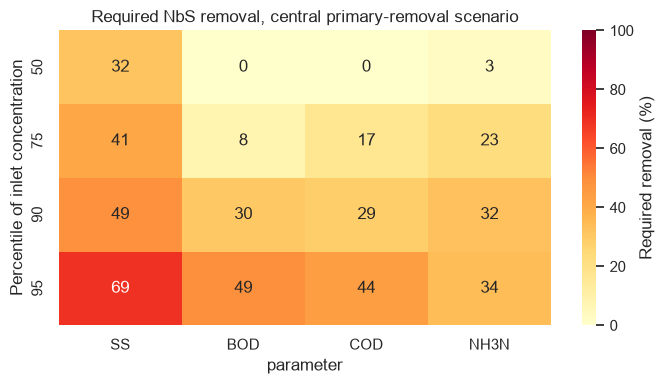

In [20]:
central = required[required["scenario"] == "Central"].pivot(index="percentile", columns="parameter",
                                                           values="required_removal_pct")[PARAMETERS]
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(central, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100,
            cbar_kws={"label": "Required removal (%)"}, ax=ax)
ax.set(title="Required NbS removal, central primary-removal scenario", ylabel="Percentile of inlet concentration")
save_fig("required_removal_heatmap")

**Analysis of required NbS removal**

The table shows the removal the NbS must achieve for storm flow to meet the permit, for each primary-removal scenario and for increasingly polluted storms (higher percentiles).

- **Suspended solids is the limiting parameter in every scenario and at every percentile.** In the central scenario it requires about 32% removal for a typical storm (50th percentile), 49% at the 90th percentile and 69% at the 95th. This is because crude concentrations are far above the 65 mg/l limit and storm dilution does little to reduce them (see section 4).
- **The other parameters need lower, similar removals.** At the 90th percentile in the central scenario, ammoniacal nitrogen needs about 32%, BOD about 30% and COD about 29%. For a typical storm (50th percentile), the central scenario needs only about 3% removal of ammoniacal nitrogen and none of BOD or COD, because after dilution and primary settlement their median concentrations are already below the permit limits.
- **The requirement rises with the percentile, with a large step between the 90th and 95th.** In the central scenario, suspended solids rises from 49% to 69%, BOD from 30% to 49% and COD from 29% to 44%, whereas ammoniacal nitrogen changes little (32% to 34%). The jump reflects one or two extreme storm samples (for example a suspended solids value of about 745 mg/l), so the 95th percentile is the least reliable result.
- **The primary-removal assumptions matter most for suspended solids and ammoniacal nitrogen.** At the 90th percentile, the suspended solids requirement ranges from about 31% (optimistic) to 49% (central) to 59% (conservative), and ammoniacal nitrogen from about 24% to 32% to 39%. BOD (25% to 35%) and COD (24% to 33%) vary less.

**Implication for the NbS:** Taking the 90th percentile as the design condition (which, with 11 samples, is effectively the second most polluted storm sample), the NbS needs to remove about 49% of suspended solids (about 59% if primary settlement performs poorly), about 32% of ammoniacal nitrogen (up to about 39%) and about 30% of BOD and COD (up to about 35%). Suspended solids should therefore be the main criterion when comparing NbS options, but each option's removal rate for every parameter should still be checked against these figures.

## 6. Summary

This section brings together the main findings from sections 3 to 5 to support the team's decisions on NbS selection and sizing. Figures come from the 2020 to 2023 flow record and the 48 matched water-quality samples (11 of them on storm days).

**Storm frequency and volume**
- Storm days (flow > 25 L/s) make up 32% of days (463 of 1,449) and group into 106 events. The number of storm days per year ranged from 78 (2022) to 144 (2023).
- Storms are seasonal: about 49% of days from October to March are storm days (peaking in December at about 64%), compared with about 15% from April to September.
- On a storm day the excess flow has a median of about 9 L/s, a 90th percentile of about 23 L/s and a maximum of about 37.5 L/s.
- The excess volume averages about 105,000 m³ per year, ranging from about 62,000 m³ (2022) to about 147,000 m³ (2023).
- A typical event lasts 2 days and produces about 890 m³ of excess flow, but a few large events dominate the total (the longest lasts 41 days and the largest produces about 53,700 m³, about 13% of the four-year total).
- Dry gaps between events have a median of 5 days and a quarter last only 1 day, so the system has little time to recover.

**Design flow**
- The share of storm volume treated shows diminishing returns: about 65% at a design flow of 10 L/s, 82% at 15 L/s, 91% at 20 L/s and 99% at 30 L/s, with 100% needing about 38 L/s.
- A design flow of about 20 L/s of excess flow (about 45 L/s total site flow) is a sensible starting point for discussion. The final choice depends on land, cost and the level of bypass allowed.

**Dilution effect**
- Storm flow dilutes ammoniacal nitrogen, BOD and COD: their medians are about 43%, 40% and 38% lower on storm days, with confidence intervals that exclude zero, and concentrations fall steadily as flow rises (Spearman rho of -0.79, -0.66 and -0.63).
- Suspended solids is not clearly diluted: its median is about 17% lower, the confidence interval includes zero and the trend levels off at about 210 mg/l above roughly 22 L/s.
- Dilution does not remove the need for treatment: all storm-day samples exceed the suspended solids limit, 73% exceed the BOD and COD limits and 55% exceed the ammoniacal nitrogen limit (crude sewage, before primary settlement).

**Required removal**

Required NbS removal at the 90th percentile of storm-day concentrations, for each primary-removal scenario (optimistic = most removal before the NbS, conservative = least):

| Parameter | Storm samples above limit (crude) | Optimistic | Central | Conservative |
|---|---|---|---|---|
| Suspended solids | 100% | 31% | 49% | 59% |
| BOD | 73% | 25% | 30% | 35% |
| COD | 73% | 24% | 29% | 33% |
| Ammoniacal nitrogen | 55% | 24% | 32% | 39% |

- Suspended solids is the limiting parameter (the one needing the highest removal) in every scenario and at every percentile. At the 90th percentile, ammoniacal nitrogen, BOD and COD need similar removals (about 29 to 32% in the central scenario), well below suspended solids.
- For a typical storm (50th percentile, central scenario) the NbS needs to remove about 32% of suspended solids and 3% of ammoniacal nitrogen, and no BOD or COD.
- The primary-removal assumptions matter most for suspended solids (31 to 59% at the 90th percentile) and ammoniacal nitrogen (24 to 39%).
- The requirement rises steeply between the 90th and 95th percentiles (for example central suspended solids from 49% to 69%) because of one or two extreme storm samples, so the 95th percentile is the least reliable result.

**Implications and next steps for the team**
1. Compare candidate NbS options first on suspended solids removal (target about 50% in the central scenario at the 90th percentile, rising to about 60% if primary settlement performs poorly). Then check ammoniacal nitrogen (about 30%, up to about 40%), BOD and COD (about 30%, up to about 35%) against the targets above.
2. Use a design flow of about 20 L/s as the working basis and test the sensitivity to 15 and 30 L/s.
3. Check that each option can hold and treat typical event volumes (about 890 m³) and cope with the larger events, and can drain and recover within the typical 1 to 5 day dry gaps. Check that it keeps its performance in winter, when storms are most frequent.

**Main limitations**
- Flow is a daily mean, so within-day peaks are hidden. The flow record ends in December 2023 (the 2024 samples cannot be used) and begins and ends on a storm day.
- Only 11 storm-day samples, reaching flows of about 47 L/s compared with a maximum of about 62.5 L/s. The 90th percentile is effectively the second-highest sample, so the required removals at high percentiles are rough.
- Water-quality values are single grab samples taken at one time of day.
- Primary-removal rates are literature-based assumptions from web sources, not site data. The ammoniacal nitrogen values (0 to 20%) are a judgement: the cited source says dissolved constituents are not affected by primary settlement but reports ammonia 5 to 26% lower in primary effluent at two plants.